# CQL versus offline DQN

I compare the saved baseline CQL models with offline DQN trained on the same data. The aim is to test whether the conservative penalty helps.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/source.json").exists())
sys.path.insert(0, str(ROOT))
OUT = ROOT / "outputs/baseline/comparison"
report = json.loads((OUT / "comparison.json").read_text())


## 1. Keep the settings fixed

Both methods use the original data splits, the same network, and training seeds 0, 1, and 2. Inputs are scaled by time and capacity; rewards are divided by 90.

- **CQL:** reuse the original models, with penalty weight 0.1.
- **Offline DQN:** train with penalty weight zero, using the same settings below.

DQN learns only from saved transitions. It does not collect new experience.

In [2]:
settings = report["protocol"]["original_training_settings"]
display(pd.Series(settings, name="Original CQL settings"))
print("Dataset: data/simulated/baseline")
print("Original model source: outputs/baseline/cql")
print("Fresh evaluation seed:", report["protocol"]["evaluation_seed"])


updates          20000.0000
batch_size         256.0000
learning_rate        0.0003
alpha                0.1000
target_update      100.0000
log_every         1000.0000
Name: Original CQL settings, dtype: float64

Dataset: data/simulated/baseline
Original model source: outputs/baseline/cql
Fresh evaluation seed: 12000000


The training settings match except for the penalty. I retain every final checkpoint and do not select or tune models using evaluation results.

## 2. Compare revenue

Both methods face the same 1,000 fresh episodes, starting at seed 12,000,000. I also calculate exact expected revenue using the known simulator.

The optimum knows the sale probabilities, but not future random sales.

,policy,exact_revenue,optimality_gap_percent,mean_revenue,mean_revenue_ci95_half_width
0,CQL seed 0,851.003,4.211,848.880,6.797
1,CQL seed 1,851.003,4.211,848.880,6.797
2,CQL seed 2,851.082,4.202,849.120,6.722
3,Offline DQN seed 0,849.447,4.386,846.585,7.330
4,Offline DQN seed 1,829.110,6.675,828.025,6.062
5,Offline DQN seed 2,815.813,8.172,813.125,5.178


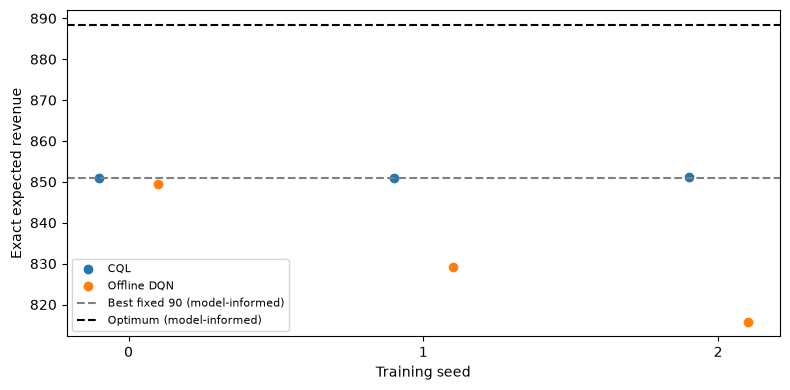

In [3]:
rows = []
for method, key in [("CQL", "cql"), ("Offline DQN", "offline_dqn")]:
    for row in report[key]:
        if row["policy"].startswith(method + " seed"):
            rows.append({"Method": method, **row})
results = pd.DataFrame(rows)
display(results[["policy", "exact_revenue", "optimality_gap_percent", "mean_revenue",
                 "mean_revenue_ci95_half_width"]].round(3))
fig, ax = plt.subplots(figsize=(8,4))
for offset, method in [(-.1,"CQL"),(.1,"Offline DQN")]:
    ax.scatter(np.arange(3)+offset, results.loc[results.Method==method,"exact_revenue"], label=method)
for row in report["cql"]:
    if row["policy"].startswith("Best fixed") or row["policy"].startswith("Optimum"):
        ax.axhline(row["exact_revenue"], linestyle="--", color="gray" if row["policy"].startswith("Best fixed") else "black", label=row["policy"])
ax.set(xticks=[0,1,2], xlabel="Training seed", ylabel="Exact expected revenue")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

CQL earns **851.00, 851.00, and 851.08**. Offline DQN earns **849.45, 829.11, and 815.81**.

CQL performs better and varies less across these seeds. DQN seed 0 is close to fixed price 90, but neither method reaches the **888.41** optimum.

## 3. Compare matched episodes

I subtract CQL revenue from DQN revenue episode by episode. Positive values favor DQN. The approximate 95% intervals describe simulation uncertainty for these fixed models, not variation across new training datasets.

In [4]:
paired = pd.DataFrame(report["paired_dqn_minus_cql"])
paired["lower"] = paired["mean"] - paired["ci95_half_width"]
paired["upper"] = paired["mean"] + paired["ci95_half_width"]
display(paired.round(3))

,seed,mean,ci95_half_width,lower,upper
0,0,-2.295,3.704,-5.999,1.409
1,1,-20.855,4.611,-25.466,-16.244
2,2,-35.995,4.285,-40.280,-31.710


## 4. Inspect the prices

Each cell shows the chosen price at a time-and-inventory state. Gray cells are unreachable. The maps show decisions, not how much training data supports them.

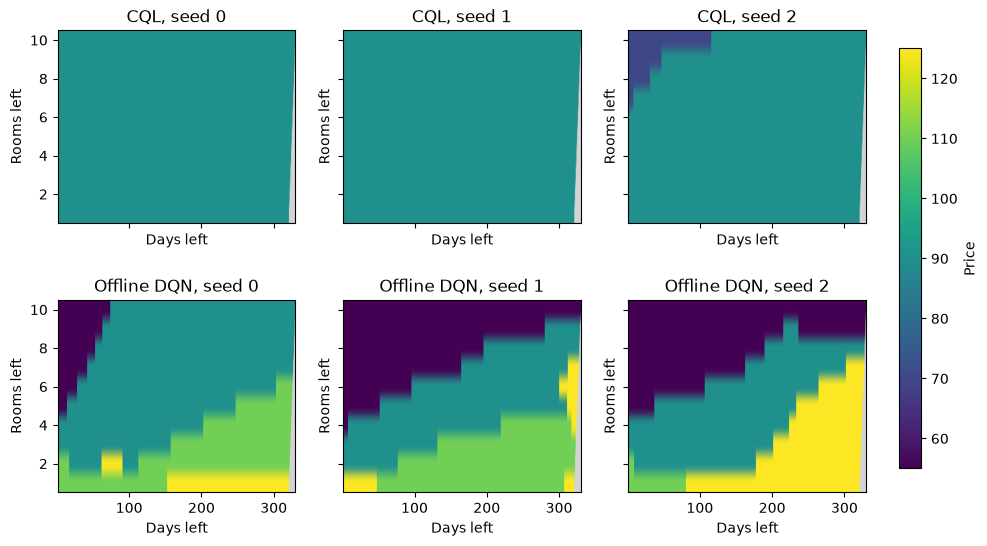

In [5]:
prices = np.array([55,70,90,110,125])
time, rooms = np.indices((331,11))
reachable = (time>0) & (rooms>0) & (10-rooms <= 330-time)
fig, axes = plt.subplots(2,3,figsize=(11,6),sharex=True,sharey=True)
for row, (method, folder) in enumerate([("CQL","cql"),("Offline DQN","offline_dqn")]):
    with np.load(OUT / folder / "policies.npz") as saved:
        for seed in [0,1,2]:
            values = prices[saved[f"{method} seed {seed}"]].astype(float)
            values[~reachable] = np.nan
            ax = axes[row,seed]
            ax.set_facecolor("lightgray")
            image = ax.imshow(values[1:,1:].T, origin="lower", aspect="auto", vmin=55, vmax=125,
                              extent=[1,330,.5,10.5], cmap="viridis")
            ax.set(title=f"{method}, seed {seed}", xlabel="Days left", ylabel="Rooms left")
fig.subplots_adjust(right=.86,hspace=.4)
fig.colorbar(image,cax=fig.add_axes([.89,.15,.02,.7]),label="Price")
plt.show()

## 5. Conclusion

Removing the conservative penalty does not improve revenue in this experiment. CQL is more consistent across the three seeds, but still mostly recovers a good fixed price.

This result applies to one dataset and these training settings. Repeating collection seeds would help check whether it holds more broadly.

Settings: [baseline_comparison.json](../../configs/baseline_comparison.json). This notebook reads saved results.